# BLAST nucleotide database search

Locate short fragments in a small local nucleotide database and verify the winning sequence, interval and strand.

BLAST uses short seed matches to find promising regions and then extends them. A tabular hit gives both a local alignment and a database-dependent expectation value. This exercise evaluates its coordinates against the generator. The subject positions printed by BLAST are one-based and inclusive.

In [1]:
from pathlib import Path
from tempfile import TemporaryDirectory
import subprocess, shutil
import numpy as np
import matplotlib.pyplot as plt
import sys

here = Path.cwd()
sys.path.insert(0, str(here.parent))
from genome_methods import rng_dna, rc

## Build and search a local database

Install NCBI BLAST+ with makeblastdb and blastn on PATH. The random strings are generated locally for this lesson.

one -> record0 111..180  bits 127  E 5e-34
two -> record1 355..276  bits 145  E 2.1e-39
three -> record2 303..376  bits 134  E 3.6e-36


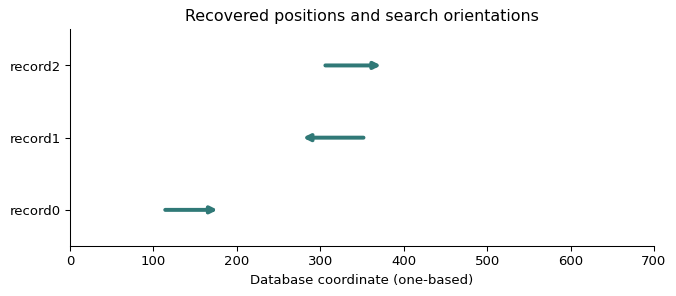

In [2]:
rng = np.random.default_rng(317)
subjects = {f"record{i}": rng_dna(rng, 700) for i in range(3)}
fixtures = [
    ("one", "record0", 110, 180, False),
    ("two", "record1", 275, 355, True),
    ("three", "record2", 302, 376, False),
]
queries = {
    q: (rc(subjects[k][a:b]) if reverse else subjects[k][a:b]) for q, k, a, b, reverse in fixtures
}


def fasta(records):
    return "".join(f">{name}\n{seq}\n" for name, seq in records.items())


with TemporaryDirectory() as where:
    root = Path(where)
    (root / "subjects.fa").write_text(fasta(subjects))
    (root / "fragments.fa").write_text(fasta(queries))
    subprocess.run(
        ["makeblastdb", "-in", "subjects.fa", "-dbtype", "nucl", "-out", "reference"],
        cwd=root,
        check=True,
        capture_output=True,
        text=True,
    )
    cmd = [
        "blastn",
        "-task",
        "blastn",
        "-query",
        "fragments.fa",
        "-db",
        "reference",
        "-dust",
        "no",
        "-num_threads",
        "1",
        "-outfmt",
        "6 qseqid sseqid sstart send bitscore evalue",
    ]
    out = subprocess.run(cmd, cwd=root, check=True, capture_output=True, text=True).stdout
best = {}
for line in out.splitlines():
    q, k, a, b, score, evalue = line.split()
    if q not in best or float(score) > best[q][3]:
        best[q] = (k, int(a), int(b), float(score), float(evalue))
fig, ax = plt.subplots(figsize=(7, 3), constrained_layout=True)
for i, (q, k, a, b, reverse) in enumerate(fixtures):
    hit, start, end, score, evalue = best[q]
    assert hit == k and (start, end) == ((b, a + 1) if reverse else (a + 1, b))
    print(f"{q} -> {hit} {start}..{end}  bits {score:g}  E {evalue:.2g}")
    ax.annotate(
        "",
        xy=(end, i),
        xytext=(start, i),
        arrowprops={"arrowstyle": "-|>", "lw": 3, "color": "#307977"},
    )
ax.set(
    xlim=(0, 700),
    ylim=(-0.5, 2.5),
    yticks=range(3),
    yticklabels=list(subjects),
    xlabel="Database coordinate (one-based)",
    title="Recovered positions and search orientations",
)
plt.show()

## Interpreting the result

A descending subject interval is a reverse-strand hit. The tiny database permits a clean coordinate check. Its E-values depend on its search space.

## Exercise

Replace the middle bases of one fragment and compare the alignment extent and bit score.

## References

[Altschul et al., BLAST (1990)](https://doi.org/10.1016/S0022-2836(05)80360-2)

[Camacho et al., BLAST+ (2009)](https://doi.org/10.1186/1471-2105-10-421)

[NCBI BLAST+ command line manual](https://www.ncbi.nlm.nih.gov/books/NBK279690/)